# Inteligencia artificial clásica · Restricciones y lógica

Dos formas clásicas de representar un problema para que lo resuelva un algoritmo general. Como **problema de satisfacción de restricciones** (CSP): variables, dominios y restricciones, resuelto con backtracking y sus mejoras (las heurísticas MRV y de grado, la comprobación hacia delante y la consistencia de arcos AC-3), y aplicado al coloreado de mapas, al sudoku y a la criptoaritmética. Y como **fórmula de lógica proposicional**: árboles, tablas de verdad, forma normal conjuntiva y el algoritmo DPLL, que decide la satisfacibilidad sin recorrer toda la tabla; con él se resuelven las $n$ reinas codificadas como SAT. El backtracking específico de las $n$ reinas, del sudoku o del coloreado de grafos está en *Recursividad*; aquí el resolvedor es uno solo y no sabe nada de cada problema.

In [1]:
import operator
import random
from collections import Counter, deque
from dataclasses import dataclass
from itertools import combinations, permutations, product

import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6, 3.2), "figure.dpi": 80})

## 1. Un CSP genérico

Escribir una clase `CSP` con un diccionario de dominios y una lista de restricciones, cada una formada por su ámbito (una tupla de variables) y un predicado. El método `consistente(var, valor, asignacion)` comprueba solo las restricciones cuyas variables ya tienen valor. Escribir `resolver(csp)` con backtracking cronológico (las variables en el orden en que se declararon), que devuelva una solución (o todas) y cuente los nodos. Comprobar el número de soluciones contra la fuerza bruta de `itertools.product` en el coloreado de grafos aleatorios pequeños.

In [2]:
class CSP:
    def __init__(self, dominios, restricciones):
        self.variables = list(dominios)
        self.dominios = {v: list(d) for v, d in dominios.items()}
        self.restricciones = restricciones
        self.de = {v: [] for v in self.variables}
        self.vecinos = {v: set() for v in self.variables}
        self.arcos_hacia = {v: [] for v in self.variables}
        for ambito, pred in restricciones:
            for v in set(ambito):
                self.de[v].append((ambito, pred))
                self.vecinos[v] |= set(ambito) - {v}
            if len(ambito) == 2:
                a, b = ambito
                self.arcos_hacia[b].append((a, b, pred))
                self.arcos_hacia[a].append((b, a, lambda y, x, p=pred: p(x, y)))

    def consistente(self, var, valor, asignacion):
        for ambito, pred in self.de[var]:
            if all(v == var or v in asignacion for v in ambito):
                if not pred(*(valor if v == var else asignacion[v] for v in ambito)):
                    return False
        return True

    def es_solucion(self, asignacion):
        return set(asignacion) == set(self.variables) and all(
            pred(*(asignacion[v] for v in ambito)) for ambito, pred in self.restricciones)


def resolver(csp, seleccion="orden", inferencia=None, todas=False):
    soluciones, nodos = [], [0]

    def legales(v, asignacion, dominios):
        return sum(csp.consistente(v, a, asignacion) for a in dominios[v])

    def elegir(asignacion, dominios):
        libres = [v for v in csp.variables if v not in asignacion]
        if seleccion == "orden":
            return libres[0]
        if seleccion == "mrv":
            return min(libres, key=lambda v: legales(v, asignacion, dominios))
        return min(libres, key=lambda v: (legales(v, asignacion, dominios),
                                          -sum(u not in asignacion for u in csp.vecinos[v])))

    def backtrack(asignacion, dominios):
        if len(asignacion) == len(csp.variables):
            soluciones.append(dict(asignacion))
            return not todas
        var = elegir(asignacion, dominios)
        for valor in dominios[var]:
            nodos[0] += 1
            if not csp.consistente(var, valor, asignacion):
                continue
            asignacion[var] = valor
            nuevos = inferir(csp, var, valor, asignacion, dominios, inferencia)
            if nuevos is not None and backtrack(asignacion, nuevos):
                return True
            del asignacion[var]
        return False

    backtrack({}, csp.dominios)
    return (soluciones if todas else (soluciones[0] if soluciones else None)), nodos[0]


def inferir(csp, var, valor, asignacion, dominios, inferencia):
    if inferencia is None:
        return dominios
    nuevos = dict(dominios)
    nuevos[var] = [valor]
    if inferencia == "fc":
        return comprobar_hacia_delante(csp, var, asignacion, nuevos)
    return ac3(csp, nuevos, cola=csp.arcos_hacia[var])


def coloreado(aristas, nodos, colores):
    return CSP({v: range(colores) for v in nodos}, [((a, b), operator.ne) for a, b in aristas])


def soluciones_fuerza_bruta(csp):
    return sum(csp.es_solucion(dict(zip(csp.variables, valores)))
               for valores in product(*(csp.dominios[v] for v in csp.variables)))


rng = random.Random(1)
for _ in range(40):
    n = rng.randint(4, 8)
    aristas = [(a, b) for a, b in combinations(range(n), 2) if rng.random() < 0.4]
    csp = coloreado(aristas, range(n), 3)
    todas, _ = resolver(csp, todas=True)
    assert all(csp.es_solucion(s) for s in todas) and len(todas) == soluciones_fuerza_bruta(csp)
print("Número de 3-coloreados igual que la fuerza bruta en 40 grafos")

Número de 3-coloreados igual que la fuerza bruta en 40 grafos


## 2. Colorear el mapa de las comunidades

Colorear el mapa de las 15 comunidades autónomas peninsulares (dos comunidades con frontera común no pueden tener el mismo color) y buscar el menor número de colores con el que es posible. Las Canarias, como no tienen frontera con nadie, se pueden colorear todas con un mismo color, ¡aunque sean siete! Contar también cuántos coloreados hay con el número mínimo de colores.

In [3]:
FRONTERAS = {
    "Galicia": ["Asturias", "Castilla y León"],
    "Asturias": ["Cantabria", "Castilla y León"],
    "Cantabria": ["País Vasco", "Castilla y León"],
    "País Vasco": ["Navarra", "La Rioja", "Castilla y León"],
    "Navarra": ["La Rioja", "Aragón"],
    "La Rioja": ["Aragón", "Castilla y León"],
    "Aragón": ["Cataluña", "Comunidad Valenciana", "Castilla-La Mancha", "Castilla y León"],
    "Cataluña": ["Comunidad Valenciana"],
    "Comunidad Valenciana": ["Castilla-La Mancha", "Región de Murcia"],
    "Región de Murcia": ["Castilla-La Mancha", "Andalucía"],
    "Andalucía": ["Castilla-La Mancha", "Extremadura"],
    "Extremadura": ["Castilla-La Mancha", "Castilla y León"],
    "Comunidad de Madrid": ["Castilla y León", "Castilla-La Mancha"],
    "Castilla y León": ["Castilla-La Mancha"],
    "Castilla-La Mancha": [],
}
aristas = [(a, b) for a, vecinas in FRONTERAS.items() for b in vecinas]
COLORES = ["rojo", "verde", "azul", "amarillo"]

for k in range(1, 5):
    solucion, nodos = resolver(coloreado(aristas, FRONTERAS, k))
    print(f"{k} {'color' if k == 1 else 'colores'}: {'sí' if solucion else 'no'} ({nodos} nodos)")
    if solucion:
        minimo = k
        break
for comunidad, color in solucion.items():
    print(f"  {comunidad:<22} {COLORES[color]}")
todas, _ = resolver(coloreado(aristas, FRONTERAS, minimo), todas=True)
print(f"Coloreados distintos con {minimo} colores: {len(todas)} (uno solo salvo permutar los colores)")
assert coloreado(aristas, FRONTERAS, minimo).es_solucion(solucion) and len(todas) % 6 == 0

islas = ["El Hierro", "La Palma", "La Gomera", "Tenerife", "Gran Canaria", "Fuerteventura", "Lanzarote"]
print("Canarias con 1 color:", resolver(coloreado([], islas, 1))[0] is not None)

1 color: no (2 nodos)
2 colores: no (22 nodos)
3 colores: sí (410 nodos)
  Galicia                rojo
  Asturias               verde
  Cantabria              rojo
  País Vasco             verde
  Navarra                azul
  La Rioja               rojo
  Aragón                 verde
  Cataluña               rojo
  Comunidad Valenciana   azul
  Región de Murcia       verde
  Andalucía              azul
  Extremadura            verde
  Comunidad de Madrid    verde
  Castilla y León        azul
  Castilla-La Mancha     rojo
Coloreados distintos con 3 colores: 6 (uno solo salvo permutar los colores)
Canarias con 1 color: True


## 3. Heurísticas MRV y de grado

El orden en que se eligen las variables importa mucho. La heurística **MRV** (*minimum remaining values*) elige la variable con menos valores legales: si alguna tiene cero, el fallo se descubre enseguida. Para desempatar, la de **grado** elige la que restringe a más variables sin asignar. Comparar los nodos que visitan el orden fijo, MRV y MRV con grado al colorear con 3 colores grafos aleatorios de 30 vértices que se pueden colorear (se construyen a partir de un coloreado escondido) y al colocar $n$ reinas como CSP (una variable por fila cuyo valor es la columna).

In [4]:
def grafo_coloreable(n, k, p, rng):
    escondido = [rng.randrange(k) for _ in range(n)]
    return [(a, b) for a, b in combinations(range(n), 2) if escondido[a] != escondido[b] and rng.random() < p]


def reinas_csp(n):
    restricciones = [((i, j), lambda a, b, d=j - i: a != b and abs(a - b) != d) for i, j in combinations(range(n), 2)]
    return CSP({i: range(n) for i in range(n)}, restricciones)


rng = random.Random(3)
grafos = [grafo_coloreable(30, 3, 0.2, rng) for _ in range(6)]
print(f"{'problema':<16} {'orden fijo':>11} {'MRV':>8} {'MRV+grado':>10}")
for nombre, csp in [*((f"grafo {i}", coloreado(g, range(30), 3)) for i, g in enumerate(grafos)),
                    *((f"{n} reinas", reinas_csp(n)) for n in (8, 12, 16))]:
    fila = []
    for seleccion in ("orden", "mrv", "mrv+grado"):
        solucion, nodos = resolver(csp, seleccion=seleccion)
        assert csp.es_solucion(solucion)
        fila.append(nodos)
    print(f"{nombre:<16} {fila[0]:>11} {fila[1]:>8} {fila[2]:>10}")

problema          orden fijo      MRV  MRV+grado


grafo 0               128212      235         80


grafo 1                63069       55         51
grafo 2                17110       53         55
grafo 3                 2168       56         58
grafo 4                52154       56         55
grafo 5                   77       55         58
8 reinas                 876      572        572


12 reinas               3066     1770       1770


16 reinas             160712      584        584


## 4. Comprobación hacia delante

Al asignar una variable, la comprobación hacia delante (*forward checking*) quita de los dominios de las variables pendientes los valores incompatibles con ella, en las restricciones en las que solo queda una variable sin asignar. Si un dominio se queda vacío, se retrocede sin seguir bajando. Implementar `comprobar_hacia_delante` (sirve también para restricciones de más de dos variables) y comparar los nodos con y sin ella en los problemas anteriores.

In [5]:
def comprobar_hacia_delante(csp, var, asignacion, dominios):
    for ambito, pred in csp.de[var]:
        libres = {v for v in ambito if v not in asignacion}
        if len(libres) != 1:
            continue
        u = libres.pop()
        dominios[u] = [b for b in dominios[u] if pred(*(b if v == u else asignacion[v] for v in ambito))]
        if not dominios[u]:
            return None
    return dominios


print(f"{'problema':<16} {'orden':>8} {'orden+FC':>9} {'MRV':>8} {'MRV+FC':>8}")
for nombre, csp in [*((f"grafo {i}", coloreado(g, range(30), 3)) for i, g in enumerate(grafos)),
                    *((f"{n} reinas", reinas_csp(n)) for n in (8, 12, 16))]:
    fila = []
    for seleccion, inferencia in [("orden", None), ("orden", "fc"), ("mrv", None), ("mrv", "fc")]:
        solucion, nodos = resolver(csp, seleccion, inferencia)
        assert csp.es_solucion(solucion)
        fila.append(nodos)
    assert fila[1] <= fila[0]
    print(f"{nombre:<16} {fila[0]:>8} {fila[1]:>9} {fila[2]:>8} {fila[3]:>8}")

problema            orden  orden+FC      MRV   MRV+FC


grafo 0            128212      4702      235       90


grafo 1             63069       825       55       30
grafo 2             17110        38       53       30
grafo 3              2168       125       56       30
grafo 4             52154        72       56       30
grafo 5                77        35       55       30
8 reinas              876        88      572       75


12 reinas            3066       193     1770      153


16 reinas          160712      7560      584       44


## 5. Consistencia de arcos: AC-3

Un arco $X \to Y$ es consistente si cada valor de $X$ tiene algún valor compatible en $Y$. AC-3 mete todos los arcos en una cola y va quitando valores sin apoyo; cuando el dominio de $X$ cambia, vuelve a encolar los arcos $Z \to X$ de sus vecinos. Implementar `ac3(csp, dominios, cola)` para restricciones binarias y probarlo: en un triángulo con dos colores no detecta nada (es arco-consistente, aunque no tiene solución), pero en el mapa con Madrid ya pintada de rojo y Castilla y León de verde deduce el color de Castilla-La Mancha y elimina valores en cadena.

In [6]:
def ac3(csp, dominios, cola=None):
    dominios = dict(dominios)
    if cola is None:
        cola = [arco for v in csp.variables for arco in csp.arcos_hacia[v]]
    cola = deque(cola)
    while cola:
        x, y, pred = cola.popleft()
        apoyados = [a for a in dominios[x] if any(pred(a, b) for b in dominios[y])]
        if len(apoyados) < len(dominios[x]):
            if not apoyados:
                return None
            dominios[x] = apoyados
            cola.extend(arco for arco in csp.arcos_hacia[x] if arco[0] != y)
    return dominios


triangulo = coloreado([(0, 1), (1, 2), (0, 2)], range(3), 2)
print("Triángulo con 2 colores, tras AC-3:", ac3(triangulo, triangulo.dominios), "| solución:", resolver(triangulo)[0])

mapa = coloreado(aristas, FRONTERAS, 3)
dominios = dict(mapa.dominios, **{"Comunidad de Madrid": [0], "Castilla y León": [1]})
reducidos = ac3(mapa, dominios)
for comunidad in FRONTERAS:
    if len(reducidos[comunidad]) < 3:
        print(f"  {comunidad:<22} {[COLORES[c] for c in reducidos[comunidad]]}")
assert reducidos["Castilla-La Mancha"] == [2]
assert ac3(mapa, dict(mapa.dominios, **{"Galicia": [0], "Asturias": [0]})) is None

Triángulo con 2 colores, tras AC-3: {0: [0, 1], 1: [0, 1], 2: [0, 1]} | solución: None
  Galicia                ['azul']
  Asturias               ['rojo']
  Cantabria              ['azul']
  País Vasco             ['rojo']
  Navarra                ['verde']
  La Rioja               ['azul']
  Aragón                 ['rojo']
  Cataluña               ['azul']
  Comunidad Valenciana   ['verde']
  Región de Murcia       ['rojo']
  Andalucía              ['verde']
  Extremadura            ['rojo']
  Comunidad de Madrid    ['rojo']
  Castilla y León        ['verde']
  Castilla-La Mancha     ['azul']


## 6. Sudoku con propagación

Plantear el sudoku como CSP: 81 variables con dominio $\{1, \dots, 9\}$ (o el valor de la pista) y una restricción $\ne$ entre cada pareja de casillas de la misma fila, columna o caja (810 restricciones). Aplicar AC-3 antes de buscar a un sudoku fácil y a uno difícil y contar las casillas que quedan resueltas, y después resolverlos combinando MRV con comprobación hacia delante y con AC-3 tras cada asignación (MAC, *maintaining arc consistency*), comparando los nodos. Comprobar que la solución respeta las pistas y que cada fila, columna y caja tiene los 9 dígitos.

In [7]:
def sudoku_csp(texto):
    casillas = [(f, c) for f in range(9) for c in range(9)]
    dominios = {(f, c): [int(texto[9 * f + c])] if texto[9 * f + c] != "0" else list(range(1, 10)) for f, c in casillas}
    companeras = [(a, b) for a, b in combinations(casillas, 2)
                  if a[0] == b[0] or a[1] == b[1] or (a[0] // 3, a[1] // 3) == (b[0] // 3, b[1] // 3)]
    return CSP(dominios, [(par, operator.ne) for par in companeras])


def valido(solucion, texto):
    filas = [[solucion[(f, c)] for c in range(9)] for f in range(9)]
    grupos = filas + [list(col) for col in zip(*filas)] + \
        [[filas[f][c] for f in range(bf, bf + 3) for c in range(bc, bc + 3)] for bf in (0, 3, 6) for bc in (0, 3, 6)]
    pistas = all(texto[9 * f + c] in ("0", str(filas[f][c])) for f in range(9) for c in range(9))
    return pistas and all(sorted(g) == list(range(1, 10)) for g in grupos)


SUDOKUS = {
    "fácil": "003020600900305001001806400008102900700000008006708200002609500800203009005010300",
    "difícil": "800000000003600000070090200050007000000045700000100030001000068008500010090000400",
}
for nombre, texto in SUDOKUS.items():
    csp = sudoku_csp(texto)
    tras_ac3 = ac3(csp, csp.dominios)
    resueltas = sum(len(d) == 1 for d in tras_ac3.values())
    print(f"{nombre}: {texto.count('0')} huecos; tras AC-3 quedan resueltas {resueltas} de 81 casillas")
    for seleccion, inferencia in [("mrv", "fc"), ("mrv", "mac")]:
        solucion, nodos = resolver(csp, seleccion, inferencia)
        assert valido(solucion, texto)
        print(f"   {seleccion.upper()} + {inferencia.upper():<3} → {nodos} nodos")
print("\n".join(" ".join(str(solucion[(f, c)]) for c in range(9)) for f in range(9)))

fácil: 49 huecos; tras AC-3 quedan resueltas 81 de 81 casillas
   MRV + FC  → 81 nodos
   MRV + MAC → 81 nodos
difícil: 60 huecos; tras AC-3 quedan resueltas 21 de 81 casillas


   MRV + FC  → 10122 nodos


   MRV + MAC → 3387 nodos
8 1 2 7 5 3 6 4 9
9 4 3 6 8 2 1 7 5
6 7 5 4 9 1 2 8 3
1 5 4 2 3 7 8 9 6
3 6 9 8 4 5 7 2 1
2 8 7 1 6 9 5 3 4
5 2 1 9 7 4 3 6 8
4 3 8 5 2 6 9 1 7
7 9 6 3 1 8 4 5 2


## 7. Criptoaritmética como CSP

En SEND + MORE = MONEY cada letra es un dígito distinto y las palabras no empiezan por 0. Plantearlo como CSP con una variable por letra y otra por cada acarreo ($c_i \in \{0, 1\}$), restricciones $\ne$ entre letras y una restricción por columna: $\text{suma de la columna} + c_i = \text{dígito del resultado} + 10\,c_{i+1}$. Escribir `criptoaritmetica(sumandos, resultado)` genérica, resolverla con MRV y comprobación hacia delante (que también poda con las restricciones de columna) y comprobar que la solución es única comparando con la fuerza bruta de todas las permutaciones de dígitos. Resolver también TWO + TWO = FOUR, contando sus soluciones.

In [8]:
def criptoaritmetica(sumandos, resultado):
    letras = sorted(set("".join(sumandos) + resultado))
    iniciales = {p[0] for p in [*sumandos, resultado]}
    n = len(resultado)
    dominios = {l: range(1 if l in iniciales else 0, 10) for l in letras}
    dominios |= {f"c{i}": [0, 1] if 0 < i < n else [0] for i in range(n + 1)}
    restricciones = [((a, b), operator.ne) for a, b in combinations(letras, 2)]
    for i in range(n):
        columna = tuple(p[-1 - i] for p in sumandos if i < len(p))
        ambito = (*columna, f"c{i}", resultado[-1 - i], f"c{i + 1}")
        restricciones.append((ambito, lambda *v: sum(v[:-3]) + v[-3] == v[-2] + 10 * v[-1]))
    return CSP(dominios, restricciones), letras


def mostrar(sumandos, resultado, solucion):
    numero = lambda palabra: int("".join(str(solucion[l]) for l in palabra))
    return " + ".join(str(numero(p)) for p in sumandos) + f" = {numero(resultado)}"


csp, letras = criptoaritmetica(["SEND", "MORE"], "MONEY")
soluciones, nodos = resolver(csp, "mrv", "fc", todas=True)
print(f"SEND + MORE = MONEY: {mostrar(['SEND', 'MORE'], 'MONEY', soluciones[0])} ({len(soluciones)} solución, {nodos} nodos)")

valor = lambda palabra, d: int("".join(str(d[l]) for l in palabra))
fuerza = [d for digitos in permutations(range(10), len(letras))
          if (d := dict(zip(letras, digitos)))["S"] and d["M"] and valor("SEND", d) + valor("MORE", d) == valor("MONEY", d)]
assert len(soluciones) == len(fuerza) == 1 and {l: soluciones[0][l] for l in letras} == fuerza[0]

csp, letras = criptoaritmetica(["TWO", "TWO"], "FOUR")
soluciones, _ = resolver(csp, "mrv", "fc", todas=True)
print(f"TWO + TWO = FOUR: {len(soluciones)} soluciones, por ejemplo", ", ".join(mostrar(["TWO", "TWO"], "FOUR", s) for s in soluciones[:3]))
assert all(2 * valor("TWO", s) == valor("FOUR", s) and len({s[l] for l in letras}) == len(letras) for s in soluciones)

SEND + MORE = MONEY: 9567 + 1085 = 10652 (1 solución, 522 nodos)


TWO + TWO = FOUR: 7 soluciones, por ejemplo 734 + 734 = 1468, 836 + 836 = 1672, 846 + 846 = 1692


## 8. Fórmulas como árboles

Representar las fórmulas de la lógica proposicional como árboles inmutables con `dataclass`: `Var`, `No`, `Y`, `O`, `Implica` y `Equivale`. Sobrecargar `~`, `&`, `|` y `>>` para escribirlas con comodidad, y escribir `__str__` (con paréntesis solo alrededor de las subfórmulas compuestas), `variables(f)` y `evaluar(f, modelo)` con `match`. Probarlo con la fórmula «si llueve en Anaga, la carretera está mojada; la carretera no está mojada; luego no llueve en Anaga».

In [9]:
class Formula:
    def __invert__(self):
        return No(self)

    def __and__(self, otra):
        return Y(self, otra)

    def __or__(self, otra):
        return O(self, otra)

    def __rshift__(self, otra):
        return Implica(self, otra)


@dataclass(frozen=True)
class Var(Formula):
    nombre: str

    def __str__(self):
        return self.nombre


@dataclass(frozen=True)
class No(Formula):
    f: Formula

    def __str__(self):
        return f"¬{envolver(self.f)}"


@dataclass(frozen=True)
class Binaria(Formula):
    a: Formula
    b: Formula
    simbolo = "?"

    def __str__(self):
        return f"{envolver(self.a)} {self.simbolo} {envolver(self.b)}"


class Y(Binaria):
    simbolo = "∧"


class O(Binaria):
    simbolo = "∨"


class Implica(Binaria):
    simbolo = "→"


class Equivale(Binaria):
    simbolo = "↔"


def envolver(f):
    return f"({f})" if isinstance(f, Binaria) else str(f)


def variables(f):
    match f:
        case Var(nombre):
            return {nombre}
        case No(g):
            return variables(g)
        case Binaria(a, b):
            return variables(a) | variables(b)


def evaluar(f, modelo):
    match f:
        case Var(nombre):
            return modelo[nombre]
        case No(g):
            return not evaluar(g, modelo)
        case Y(a, b):
            return evaluar(a, modelo) and evaluar(b, modelo)
        case O(a, b):
            return evaluar(a, modelo) or evaluar(b, modelo)
        case Implica(a, b):
            return not evaluar(a, modelo) or evaluar(b, modelo)
        case Equivale(a, b):
            return evaluar(a, modelo) == evaluar(b, modelo)


llueve, mojada = Var("llueve"), Var("mojada")
modus_tollens = ((llueve >> mojada) & ~mojada) >> ~llueve
print(modus_tollens, "| variables:", sorted(variables(modus_tollens)))
print("Con llueve=V, mojada=F:", evaluar(modus_tollens, {"llueve": True, "mojada": False}))
assert Y(llueve, mojada) == (llueve & mojada) and len({llueve & mojada, Y(Var("llueve"), Var("mojada"))}) == 1

((llueve → mojada) ∧ ¬mojada) → ¬llueve | variables: ['llueve', 'mojada']
Con llueve=V, mojada=F: True


## 9. Tablas de verdad

Escribir `tabla_de_verdad(f)`, que muestre todas las combinaciones de valores, y a partir de ella `es_tautologia`, `es_satisfacible` y `son_equivalentes`. Comprobar que el *modus tollens* del ejercicio anterior es una tautología, que $p \land \lnot p$ es insatisfacible, las dos leyes de De Morgan, que una implicación equivale a su contrarrecíproca pero no a su recíproca y que $p \to (q \to r)$ equivale a $(p \land q) \to r$.

In [10]:
def modelos(nombres):
    for valores in product([False, True], repeat=len(nombres)):
        yield dict(zip(nombres, valores))


def tabla_de_verdad(f):
    nombres = sorted(variables(f))
    print(" ".join(nombres), "│", f)
    for m in modelos(nombres):
        print(" ".join(f"{'V' if m[n] else 'F':^{len(n)}}" for n in nombres), "│", "V" if evaluar(f, m) else "F")


def es_tautologia(f):
    return all(evaluar(f, m) for m in modelos(sorted(variables(f))))


def es_satisfacible(f):
    return any(evaluar(f, m) for m in modelos(sorted(variables(f))))


def son_equivalentes(f, g):
    return es_tautologia(Equivale(f, g))


p, q, r = Var("p"), Var("q"), Var("r")
tabla_de_verdad(p >> q)
assert es_tautologia(modus_tollens) and not es_satisfacible(p & ~p)
assert son_equivalentes(~(p & q), ~p | ~q) and son_equivalentes(~(p | q), ~p & ~q)
assert son_equivalentes(p >> q, ~q >> ~p) and not son_equivalentes(p >> q, q >> p)
assert son_equivalentes(p >> (q >> r), (p & q) >> r)
print("Leyes comprobadas")

p q │ p → q
F F │ V
F V │ V
V F │ F
V V │ V
Leyes comprobadas


## 10. Forma normal conjuntiva

Una fórmula está en forma normal conjuntiva (FNC) si es una conjunción de cláusulas, y cada cláusula es una disyunción de literales ($p$ o $\lnot p$). Pasar a FNC en tres pasos: eliminar $\leftrightarrow$ y $\to$, llevar las negaciones hasta las variables (De Morgan y doble negación) y distribuir $\lor$ sobre $\land$. Representar el resultado como un conjunto de cláusulas (`frozenset` de literales `(nombre, signo)`), quitando las tautológicas. Comprobar en 300 fórmulas aleatorias que la FNC tiene la misma tabla de verdad que la original, y mostrar cómo crece con la distribución.

In [11]:
def sin_implicaciones(f):
    match f:
        case Var():
            return f
        case No(g):
            return No(sin_implicaciones(g))
        case Implica(a, b):
            return O(No(sin_implicaciones(a)), sin_implicaciones(b))
        case Equivale(a, b):
            a, b = sin_implicaciones(a), sin_implicaciones(b)
            return Y(O(No(a), b), O(No(b), a))
        case Y(a, b):
            return Y(sin_implicaciones(a), sin_implicaciones(b))
        case O(a, b):
            return O(sin_implicaciones(a), sin_implicaciones(b))


def negaciones_dentro(f):
    match f:
        case No(No(g)):
            return negaciones_dentro(g)
        case No(Y(a, b)):
            return O(negaciones_dentro(No(a)), negaciones_dentro(No(b)))
        case No(O(a, b)):
            return Y(negaciones_dentro(No(a)), negaciones_dentro(No(b)))
        case Y(a, b):
            return Y(negaciones_dentro(a), negaciones_dentro(b))
        case O(a, b):
            return O(negaciones_dentro(a), negaciones_dentro(b))
        case _:
            return f


def clausulas(f):
    match f:
        case Var(nombre):
            return {frozenset({(nombre, True)})}
        case No(Var(nombre)):
            return {frozenset({(nombre, False)})}
        case Y(a, b):
            return clausulas(a) | clausulas(b)
        case O(a, b):
            return {x | y for x in clausulas(a) for y in clausulas(b)}


def fnc(f):
    resultado = clausulas(negaciones_dentro(sin_implicaciones(f)))
    return {c for c in resultado if not any((n, not s) in c for n, s in c)}


def texto_fnc(cls):
    literal = lambda n, s: n if s else f"¬{n}"
    return " ∧ ".join("(" + " ∨ ".join(literal(*l) for l in sorted(c)) + ")" for c in sorted(cls, key=sorted))


def evaluar_fnc(cls, modelo):
    return all(any(modelo[n] == s for n, s in c) for c in cls)


def formula_aleatoria(profundidad, rng, nombres="pqrs"):
    if profundidad == 0 or rng.random() < 0.2:
        return Var(rng.choice(nombres))
    if rng.random() < 0.2:
        return No(formula_aleatoria(profundidad - 1, rng))
    tipo = rng.choice([Y, O, Implica, Equivale])
    return tipo(formula_aleatoria(profundidad - 1, rng), formula_aleatoria(profundidad - 1, rng))


print(p >> (q & r), "  ≡  ", texto_fnc(fnc(p >> (q & r))))
print(Equivale(p, q), "  ≡  ", texto_fnc(fnc(Equivale(p, q))))
print(modus_tollens, "  ≡  ", texto_fnc(fnc(modus_tollens)) or "(sin cláusulas: tautología)")

rng = random.Random(10)
tamanos = []
for _ in range(300):
    f = formula_aleatoria(4, rng)
    cls = fnc(f)
    nombres = sorted(variables(f))
    assert all(evaluar(f, m) == evaluar_fnc(cls, m) for m in modelos(nombres))
    tamanos.append(len(cls))
print("Cláusulas en las 300 FNC: máximo", max(tamanos), "| media", round(sum(tamanos) / len(tamanos), 1))

p → (q ∧ r)   ≡   (¬p ∨ q) ∧ (¬p ∨ r)
p ↔ q   ≡   (¬p ∨ q) ∧ (p ∨ ¬q)
((llueve → mojada) ∧ ¬mojada) → ¬llueve   ≡   (sin cláusulas: tautología)
Cláusulas en las 300 FNC: máximo 17 | media 2.7


## 11. DPLL frente a la tabla de verdad

El algoritmo DPLL decide si un conjunto de cláusulas es satisfacible sin recorrer los $2^n$ modelos: aplica la **propagación unitaria** (una cláusula de un solo literal obliga a su valor), elimina los **literales puros** (los que solo aparecen con un signo se pueden hacer ciertos) y, si no queda nada que deducir, **ramifica** sobre la variable más frecuente. Escribir `dpll(clausulas)` con literales enteros (como en el formato DIMACS: $3$ es $x_3$ y $-3$ es $\lnot x_3$), comprobarlo contra la tabla de verdad en 3-SAT aleatorios de 10 variables, y dibujar la **transición de fase**: con 20 variables, el porcentaje de fórmulas satisfacibles cae bruscamente cuando la razón cláusulas/variables pasa por $\approx 4{,}26$, y es en esa zona donde DPLL más trabaja (con tan pocas variables, el pico aparece algo desplazado).

DPLL coincide con la tabla de verdad en 200 fórmulas de 10 variables
m/n = 2    satisfacibles: 100.0 %   nodos medios:    5.5
m/n = 3    satisfacibles: 100.0 %   nodos medios:    8.0
m/n = 3.5  satisfacibles:  97.5 %   nodos medios:    9.6
m/n = 4    satisfacibles:  92.5 %   nodos medios:   12.2
m/n = 4.25 satisfacibles:  82.5 %   nodos medios:   12.6
m/n = 4.5  satisfacibles:  62.5 %   nodos medios:   14.3
m/n = 5    satisfacibles:  25.0 %   nodos medios:   17.1


m/n = 6    satisfacibles:   2.5 %   nodos medios:   14.1
m/n = 7    satisfacibles:   0.0 %   nodos medios:   12.9


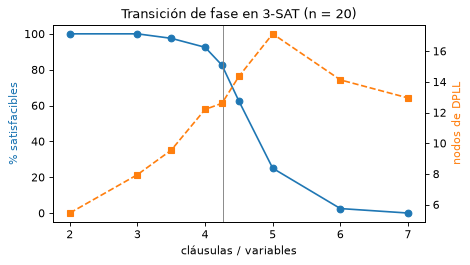

In [12]:
def simplificar(clausulas, literal):
    return [c - {-literal} for c in clausulas if literal not in c]


def dpll(clausulas, modelo=frozenset(), nodos=None):
    if nodos is not None:
        nodos[0] += 1
    while True:
        if any(not c for c in clausulas):
            return None
        unitaria = next((next(iter(c)) for c in clausulas if len(c) == 1), None)
        if unitaria is None:
            break
        modelo, clausulas = modelo | {unitaria}, simplificar(clausulas, unitaria)
    literales = {l for c in clausulas for l in c}
    for l in literales:
        if -l not in literales:
            modelo, clausulas = modelo | {l}, simplificar(clausulas, l)
    if not clausulas:
        return modelo
    variable = Counter(abs(l) for c in clausulas for l in c).most_common(1)[0][0]
    for literal in (variable, -variable):
        resultado = dpll(simplificar(clausulas, literal), modelo | {literal}, nodos)
        if resultado is not None:
            return resultado
    return None


def tres_sat(n, m, rng):
    return [frozenset(v * rng.choice((1, -1)) for v in rng.sample(range(1, n + 1), 3)) for _ in range(m)]


def satisfacible_por_tabla(clausulas, n):
    return any(all(any((l > 0) == valores[abs(l) - 1] for l in c) for c in clausulas)
               for valores in product([False, True], repeat=n))


rng = random.Random(11)
for _ in range(200):
    clausulas = tres_sat(10, rng.randint(20, 60), rng)
    modelo = dpll(clausulas)
    assert (modelo is not None) == satisfacible_por_tabla(clausulas, 10)
    if modelo is not None:
        assert all(c & modelo for c in clausulas)
print("DPLL coincide con la tabla de verdad en 200 fórmulas de 10 variables")

razones = [2, 3, 3.5, 4, 4.25, 4.5, 5, 6, 7]
porcentaje, esfuerzo = [], []
for razon in razones:
    resultados = []
    for _ in range(40):
        nodos = [0]
        resultados.append((dpll(tres_sat(20, round(20 * razon), rng), nodos=nodos) is not None, nodos[0]))
    porcentaje.append(100 * sum(s for s, _ in resultados) / len(resultados))
    esfuerzo.append(sum(n for _, n in resultados) / len(resultados))
    print(f"m/n = {razon:<4} satisfacibles: {porcentaje[-1]:5.1f} %   nodos medios: {esfuerzo[-1]:6.1f}")

fig, ax = plt.subplots()
ax.plot(razones, porcentaje, "o-", color="C0")
ax.set_xlabel("cláusulas / variables")
ax.set_ylabel("% satisfacibles", color="C0")
ax2 = ax.twinx()
ax2.plot(razones, esfuerzo, "s--", color="C1")
ax2.set_ylabel("nodos de DPLL", color="C1")
ax.axvline(4.26, color="gray", lw=0.8)
ax.set_title("Transición de fase en 3-SAT (n = 20)")
plt.show()

## 12. Las $n$ reinas como SAT

Codificar las $n$ reinas en cláusulas con una variable $x_{f,c}$ por casilla: en cada fila hay al menos una reina (una cláusula con $n$ literales) y en cada fila, columna y diagonal hay como mucho una (para cada pareja de casillas, $\lnot x_a \lor \lnot x_b$). Resolver el tablero de 8 con `dpll` y dibujarlo. Para contar todas las soluciones, añadir tras cada una una **cláusula de bloqueo** que prohíba exactamente esa colocación y volver a llamar a DPLL hasta que sea insatisfacible; comparar los recuentos para $n = 4, \dots, 7$ con las permutaciones que no tienen dos reinas en la misma diagonal.

In [13]:
def reinas_sat(n):
    x = lambda f, c: f * n + c + 1
    casillas = [(f, c) for f in range(n) for c in range(n)]
    clausulas = [frozenset(x(f, c) for c in range(n)) for f in range(n)]
    for (f1, c1), (f2, c2) in combinations(casillas, 2):
        if f1 == f2 or c1 == c2 or abs(f1 - f2) == abs(c1 - c2):
            clausulas.append(frozenset({-x(f1, c1), -x(f2, c2)}))
    return clausulas


def colocacion(modelo, n):
    return tuple(sorted(divmod(l - 1, n) for l in modelo if l > 0))


def contar_por_sat(n):
    clausulas, soluciones = reinas_sat(n), []
    while (modelo := dpll(clausulas)) is not None:
        reinas = colocacion(modelo, n)
        soluciones.append(reinas)
        clausulas.append(frozenset(-(f * n + c + 1) for f, c in reinas))
    return soluciones


def contar_por_permutaciones(n):
    return sum(all(abs(p[i] - p[j]) != j - i for i, j in combinations(range(n), 2)) for p in permutations(range(n)))


n = 8
clausulas = reinas_sat(n)
reinas = colocacion(dpll(clausulas), n)
print(f"{n} reinas: {n * n} variables, {len(clausulas)} cláusulas")
print("\n".join(" ".join("♛" if (f, c) in reinas else "·" for c in range(n)) for f in range(n)))
assert len(reinas) == n and len({c for _, c in reinas}) == n and reinas_csp(n).es_solucion(dict(reinas))

for n in range(4, 8):
    soluciones = contar_por_sat(n)
    print(f"n = {n}: {len(soluciones)} soluciones")
    assert len(soluciones) == len(set(soluciones)) == contar_por_permutaciones(n)

8 reinas: 64 variables, 736 cláusulas
· · · · ♛ · · ·
· · · · · · ♛ ·
· ♛ · · · · · ·
· · · ♛ · · · ·
· · · · · · · ♛
♛ · · · · · · ·
· · ♛ · · · · ·
· · · · · ♛ · ·
n = 4: 2 soluciones
n = 5: 10 soluciones
n = 6: 4 soluciones


n = 7: 40 soluciones
